# Auditing the MMIB counterfactual VQA datasets

MMIB tests whether vision-language models answer questions about a scene by reasoning about its content or by exploiting shortcuts. Each item is a **triplet**: an original scene, a **semantic counterfactual** (CF1) edited so that the answer should change, and a **perturbation** (CF2) that should leave the answer unchanged. All three images are asked three questions (the original question and one written for each counterfactual), giving a 3×3 answer matrix per triplet.

This notebook audits the dataset used for the MMIB poster at the Sci-FM workshop, COLM 2026, and compares it with a regenerated version:

- **Paper dataset**: the 100-triplet CLEVR set linked from the paper ([`AnonymousECCV15285/MMIB_Counterfactual_image_Dataset`](https://huggingface.co/datasets/AnonymousECCV15285/MMIB_Counterfactual_image_Dataset)). The same rows are public as v1.0 of [`scholo/MMB_dataset`](https://huggingface.co/datasets/scholo/MMB_dataset); the notebook checks this.
- **Regenerated set**: produced with the updated generator, which adds validation checks and answer-balance quotas. It is published as v1.1 of [`scholo/MMB_dataset`](https://huggingface.co/datasets/scholo/MMB_dataset). A run with the checks but without the quotas separates the effect of the two changes.

Every figure is computed below from the loaded data. Only text columns are read from the Hub, so no images are downloaded. Requires `pandas`, `pyarrow`, `matplotlib` and `huggingface_hub`.

## Definitions

- **Flip rate**: the share of semantic counterfactuals for which the counterfactual's own question gets a different answer on the edited image than on the original. This is the property the benchmark is designed to have.
- **Original-question flip rate**: the same comparison using the original question.
- **Hold rate**: the share of perturbations for which the original question's answer is unchanged. Where `occlusion_change` appears in the counterfactual slot, it is scored as a perturbation, since hiding part of an object should not change the answer.
- **Majority baseline**: the accuracy of always giving the most common answer for a question type. A high value means a model can score well without looking at the image.
- Intervals are 95% Wilson score intervals. Comparisons with the paper dataset use a two-sided Fisher exact test.

In [1]:
import json
import math
from collections import Counter, defaultdict
from pathlib import Path

import pandas as pd
import pyarrow.parquet as pq
from huggingface_hub import HfFileSystem
from IPython.display import Image, Markdown, display
from matplotlib.figure import Figure

# Works in two places: inside the generator repo (where local runs live under output/),
# or in a standalone copy of this notebook, which loads everything from the Hub.
_here = Path.cwd().resolve()
_candidates = [_here, *_here.parents, _here / "MMB-Counterfactual-Image-Generation-Tool"]
GENERATOR_ROOT = next((p for p in _candidates if (p / "pipeline.py").exists()), None)
NOTEBOOK_DIR = GENERATOR_ROOT / "notebooks" if GENERATOR_ROOT else _here
METRICS_PATH = NOTEBOOK_DIR / "audit_metrics.json"

# Released datasets, pinned to the commits audited here.
HUB_RELEASES = {
    "paper": ("AnonymousECCV15285/MMIB_Counterfactual_image_Dataset", "57454736f851e8c8b77ffe5eae613560e8e041ce"),
}
# The public copy of the paper dataset (v1.0 of scholo/MMB_dataset), checked row for row below.
PUBLIC_COPY = ("scholo/MMB_dataset", "2087f6127550c5912f14a3fe6c9ef46d51b562f8")
# Published regenerated set. Used when the local run is not available.
REGENERATED_HUB = ("scholo/MMB_dataset", "v1.1")

LOCAL_RUNS = {} if GENERATOR_ROOT is None else {
    "checks_only": GENERATOR_ROOT / "output" / "dataset_v1_1" / "image_mapping_with_questions.csv",
    "regenerated": GENERATOR_ROOT / "output" / "dataset_v1_1b" / "image_mapping_with_questions.csv",
}
LABELS = {
    "paper": "Paper dataset",
    "checks_only": "Regenerated, checks only",
    "regenerated": "Regenerated",
}
PRIMARY = "paper"

IMAGE_CF_TYPES = {
    "change_color", "change_shape", "change_size", "change_material",
    "change_position", "add_object", "remove_object", "replace_object",
    "swap_attribute", "relational_flip",
}
NEGATIVE_CF_TYPES = {
    "change_background", "change_lighting", "add_noise",
    "apply_fisheye", "apply_blur", "apply_vignette", "apply_chromatic_aberration",
    "occlusion_change",
}
UNRESOLVED = {"not found", "unknown", "none", "", "nan", "null"}

# The checks-only run was not instrumented. Its generation log records 30 scenes that
# exhausted 150 precheck retries and 100 kept scenes, which gives a lower bound on attempts.
CHECKS_ONLY_LOG = {"failed_scenes": 30, "max_retries": 150, "kept": 100}

# Rejection reasons recorded by the instrumented generator, grouped for reporting.
REJECT_CATEGORY = {
    "cf1_question_none": "No usable CF1 question template",
    "cf1_template_group": "No usable CF1 question template",
    "cf1_questions_same_answer": "Flip check",
    "quota": "Answer-balance quota",
    "unresolved": "Unresolved answer",
}

In [2]:
def classify_answer_type(question):
    ql = (question or "").strip().lower()
    if not ql:
        return "other"
    if "matte or shiny" in ql or ("finish" in ql and "matte" in ql and "shiny" in ql):
        return "attribute"
    if (
        ql.startswith("how many")
        or "total number" in ql
        or ql.startswith("what is the total")
        or "what is the count" in ql
    ):
        return "count"
    if ql.startswith("what "):
        return "attribute"
    if (
        ql.startswith(("is ", "are ", "do ", "does "))
        or "equal to" in ql
        or "equal number" in ql
        or "exactly as many" in ql
        or "at least" in ql
        or "fewer than" in ql
        or "more than" in ql
    ):
        return "yes/no"
    return "other"


def normalize_answer(value):
    if value is None or pd.isna(value):
        return ""
    return str(value).strip().lower()


def _first_present(row, names):
    for name in names:
        if name in row.index and pd.notna(row[name]):
            return row[name]
    for name in names:
        if name in row.index:
            return row[name]
    return None


# v1 and v1.1 use different column names for the same fields.
CANONICAL = {
    "cf1_type": ["counterfactual1_type", "semantic_counterfactual_type"],
    "cf2_type": ["counterfactual2_type", "negative_counterfactual_type"],
    "orig_q": ["original_question"],
    "cf1_q": ["counterfactual1_question", "semantic_counterfactual_question_1"],
    "cf2_q": ["counterfactual2_question", "negative_counterfactual_question_1"],
    "cf1_skill": [
        "counterfactual1_question_difficulty",
        "semantic_counterfactual_question_1_reasoning_op",
        "semantic_counterfactual_question_1_difficulty",
    ],
    "orig_on_orig": ["original_image_answer_to_original_question"],
    "cf1q_on_orig": [
        "original_image_answer_to_cf1_question",
        "original_image_answer_to_semantic_counterfactual_question_1",
    ],
    "cf2q_on_orig": [
        "original_image_answer_to_cf2_question",
        "original_image_answer_to_negative_counterfactual_question_1",
    ],
    "orig_on_cf1": [
        "cf1_image_answer_to_original_question",
        "semantic_counterfactual_image_answer_to_original_question",
    ],
    "cf1q_on_cf1": [
        "cf1_image_answer_to_cf1_question",
        "semantic_counterfactual_image_answer_to_semantic_counterfactual_question_1",
    ],
    "cf2q_on_cf1": [
        "cf1_image_answer_to_cf2_question",
        "semantic_counterfactual_image_answer_to_negative_counterfactual_question_1",
    ],
    "orig_on_cf2": [
        "cf2_image_answer_to_original_question",
        "negative_counterfactual_image_answer_to_original_question",
    ],
    "cf1q_on_cf2": [
        "cf2_image_answer_to_cf1_question",
        "negative_counterfactual_image_answer_to_semantic_counterfactual_question_1",
    ],
    "cf2q_on_cf2": [
        "cf2_image_answer_to_cf2_question",
        "negative_counterfactual_image_answer_to_negative_counterfactual_question_1",
    ],
}

# (image, question, answer column, answer-type column) for the nine cells of the matrix.
NINE_CELLS = [
    ("Original image", "original question", "orig_on_orig", "orig_type"),
    ("Original image", "CF1 question", "cf1q_on_orig", "cf1_type_q"),
    ("Original image", "CF2 question", "cf2q_on_orig", "cf2_type_q"),
    ("CF1 image", "original question", "orig_on_cf1", "orig_type"),
    ("CF1 image", "CF1 question", "cf1q_on_cf1", "cf1_type_q"),
    ("CF1 image", "CF2 question", "cf2q_on_cf1", "cf2_type_q"),
    ("CF2 image", "original question", "orig_on_cf2", "orig_type"),
    ("CF2 image", "CF1 question", "cf1q_on_cf2", "cf1_type_q"),
    ("CF2 image", "CF2 question", "cf2q_on_cf2", "cf2_type_q"),
]
ANSWER_COLUMNS = [cell[2] for cell in NINE_CELLS]


def drop_image_columns(columns):
    return [c for c in columns if "image" in c.lower() and "answer" not in c.lower()]


def wilson_ci(k, n, z=1.96):
    if not n:
        return None, None
    p = k / n
    z2 = z * z
    denom = 1.0 + z2 / n
    center = (p + z2 / (2.0 * n)) / denom
    margin = (z / denom) * math.sqrt(p * (1.0 - p) / n + z2 / (4.0 * n * n))
    return center - margin, center + margin


def _log_choose(n, k):
    if k < 0 or k > n:
        return float("-inf")
    k = min(k, n - k)
    return sum(math.log(n - i) - math.log(i + 1) for i in range(k))


def fisher_exact_two_sided(a, b, c, d):
    """Two-sided Fisher exact p-value for the 2x2 table [[a, b], [c, d]]."""
    n1, n2, k = a + b, c + d, a + c
    n = n1 + n2
    if n == 0:
        return 1.0

    def prob(x):
        if x < max(0, k - n2) or x > min(k, n1):
            return 0.0
        return math.exp(_log_choose(n1, x) + _log_choose(n2, k - x) - _log_choose(n, k))

    p_obs = prob(a)
    total = sum(prob(x) for x in range(max(0, k - n2), min(k, n1) + 1) if prob(x) <= p_obs + 1e-12)
    return min(1.0, total)


def pct(x):
    return "n/a" if x is None else f"{100 * x:.1f}%"


def fmt_ci(ci):
    lo, hi = ci
    return "n/a" if lo is None else f"{100 * lo:.0f}–{100 * hi:.0f}%"


def rate_cell(hits, n, ci=None):
    """Table format: 48.8% (42/86; 39–59%)."""
    if not n:
        return "n/a"
    detail = f"{hits}/{n}" + (f"; {fmt_ci(ci)}" if ci else "")
    return f"{pct(hits / n)} ({detail})"


def rate_prose(hits, n, ci=None):
    """Prose format: 48.8% (42/86; 95% CI 39–59%)."""
    detail = f"{hits}/{n}" + (f"; 95% CI {fmt_ci(ci)}" if ci else "")
    return f"{pct(hits / n)} ({detail})"


def join_words(items):
    items = list(items)
    return items[0] if len(items) == 1 else ", ".join(items[:-1]) + " and " + items[-1]


def json_ready(obj):
    if isinstance(obj, dict):
        return {str(k): json_ready(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [json_ready(v) for v in obj]
    return obj

In [3]:
def canonicalize(raw):
    missing = [key for key, names in CANONICAL.items() if not any(n in raw.columns for n in names)]
    if missing:
        raise KeyError(f"No column found for {missing}. Columns present: {list(raw.columns)}")
    rows = []
    for _, row in raw.iterrows():
        rec = {key: _first_present(row, names) for key, names in CANONICAL.items()}
        rec["orig_type"] = classify_answer_type(rec["orig_q"])
        rec["cf1_type_q"] = classify_answer_type(rec["cf1_q"])
        rec["cf2_type_q"] = classify_answer_type(rec["cf2_q"])
        for key in ANSWER_COLUMNS:
            rec[key] = normalize_answer(rec[key])
        rec["cf1_type"] = normalize_answer(rec["cf1_type"]).replace(" ", "_")
        rec["cf2_type"] = normalize_answer(rec["cf2_type"]).replace(" ", "_")
        rows.append(rec)
    return pd.DataFrame(rows)


def majority_baselines(frame):
    """Accuracy of always answering the most common answer, per original-question type."""
    out = {}
    for atype in ("count", "yes/no", "attribute", "other"):
        answers = frame.loc[frame["orig_type"] == atype, "orig_on_orig"]
        n = int(len(answers))
        entry = {"n": n, "mode": None, "mode_hits": 0, "mode_accuracy": None}
        if n:
            mode, hits = Counter(answers).most_common(1)[0]
            entry.update(mode=mode, mode_hits=int(hits), mode_accuracy=hits / n,
                         mode_accuracy_ci=list(wilson_ci(hits, n)))
            if atype == "yes/no":
                yes = int((answers == "yes").sum())
                entry.update(yes_hits=yes, yes_share=yes / n, yes_share_ci=list(wilson_ci(yes, n)))
        out[atype] = entry
    return out


def flip_hold(frame):
    def table(counts):
        return [{"type": t, "n": v["n"], "hits": v["hits"], "rate": v["hits"] / v["n"] if v["n"] else None}
                for t, v in sorted(counts.items())]

    design = defaultdict(lambda: {"n": 0, "hits": 0})
    origq = defaultdict(lambda: {"n": 0, "hits": 0})
    hold = defaultdict(lambda: {"n": 0, "hits": 0})
    unknown = Counter()
    for _, row in frame.iterrows():
        t1, t2 = row["cf1_type"], row["cf2_type"]
        if t1 in IMAGE_CF_TYPES:
            design[t1]["n"] += 1
            design[t1]["hits"] += int(row["cf1q_on_orig"] != row["cf1q_on_cf1"])
            origq[t1]["n"] += 1
            origq[t1]["hits"] += int(row["orig_on_orig"] != row["orig_on_cf1"])
        elif t1 in NEGATIVE_CF_TYPES:
            hold[t1]["n"] += 1
            hold[t1]["hits"] += int(row["orig_on_orig"] == row["orig_on_cf1"])
        elif t1:
            unknown[t1] += 1
        if t2 in NEGATIVE_CF_TYPES:
            hold[t2]["n"] += 1
            hold[t2]["hits"] += int(row["orig_on_orig"] == row["orig_on_cf2"])
        elif t2 and t2 not in IMAGE_CF_TYPES:
            unknown[t2] += 1

    image = frame[frame["cf1_type"].isin(IMAGE_CF_TYPES)]
    yes_no = image[image["cf1_type_q"] == "yes/no"]
    stuck_yes = int(((yes_no["cf1q_on_orig"] == "yes") & (yes_no["cf1q_on_cf1"] == "yes")).sum())

    out = {"unknown_cf_types": dict(unknown), "cf1_yes_both_images": stuck_yes}
    for name, counts in (("design", design), ("origq", origq), ("hold", hold)):
        n = sum(v["n"] for v in counts.values())
        hits = sum(v["hits"] for v in counts.values())
        out[f"{name}_n"], out[f"{name}_hits"] = n, hits
        out[f"{name}_rate"] = hits / n if n else None
        out[f"{name}_ci"] = list(wilson_ci(hits, n))
        out[f"{name}_by_type"] = table(counts)
    out["design_flip_ceiling"] = (out["design_n"] - stuck_yes) / out["design_n"] if out["design_n"] else None
    return out


def defect_report(raw, frame):
    unresolved = [
        {"row": int(i), "cell": f"{img} × {q}", "value": row[col] or "<empty>",
         "original_question": row["orig_q"], "cf1_type": row["cf1_type"]}
        for i, row in frame.iterrows()
        for img, q, col, _ in NINE_CELLS
        if row[col] in UNRESOLVED
    ]
    nunique = raw.nunique(dropna=False)
    constant = [
        {"column": c, "value": None if pd.isna(raw[c].iloc[0]) else str(raw[c].iloc[0])}
        for c in raw.columns if len(raw) and int(nunique[c]) <= 1
    ]
    return {
        "unresolved_n": len(unresolved),
        "unresolved_rows": unresolved,
        "constant_columns": constant,
        "duplicate_rows": int(raw.duplicated().sum()),
        "duplicate_question_triples": int(frame.duplicated(subset=["orig_q", "cf1_q", "cf2_q"]).sum()),
        "cf1_skill_values": sorted(frame["cf1_skill"].astype(str).unique().tolist()),
    }


def load_acceptance(run_dir, version):
    path = Path(run_dir) / "acceptance_stats.json" if run_dir else None
    if path is not None and path.exists():
        stats = json.loads(path.read_text(encoding="utf-8"))
        attempts = stats.get("precheck_attempts") or stats.get("attempts")
        accepted = stats.get("precheck_accepted") or stats.get("accepted")
        return {
            "source": "instrumented",
            "attempts": attempts,
            "accepted": accepted,
            "attempts_per_kept": attempts / accepted if attempts and accepted else None,
            "reject_reasons": stats.get("reject_reasons") or {},
            "quota_fallbacks": stats.get("quota_fallbacks"),
        }
    if version == "checks_only":
        log = CHECKS_ONLY_LOG
        attempts = log["failed_scenes"] * log["max_retries"] + log["kept"]
        return {
            "source": "generation log (lower bound)",
            "attempts": attempts,
            "accepted": log["kept"],
            "attempts_per_kept": attempts / log["kept"],
            "reject_reasons": {},
        }
    return {"source": "not recorded"}


def analyze(raw, source, version, run_dir=None):
    frame = canonicalize(raw)
    metrics = {
        "version": version,
        "source": source,
        "n_rows": int(len(raw)),
        "answer_types": frame["orig_type"].value_counts().to_dict(),
        "baselines": majority_baselines(frame),
        **flip_hold(frame),
        **defect_report(raw, frame),
        "acceptance": load_acceptance(run_dir, version),
    }
    return frame, metrics

In [4]:
FS = HfFileSystem()


def load_hub_text(repo_id, revision):
    """Read only the non-image columns of a Hub dataset's train split."""
    root = f"datasets/{repo_id}@{revision}" if revision else f"datasets/{repo_id}"
    files = sorted(FS.glob(f"{root}/data/train-*.parquet")) or sorted(FS.glob(f"{root}/data/train.parquet"))
    if not files:
        raise FileNotFoundError(f"No train parquet files found in {repo_id}")
    names = pq.read_schema(FS.open(files[0])).names
    keep = [c for c in names if c not in drop_image_columns(names)]
    frame = pd.concat([pd.read_parquet(FS.open(f), columns=keep) for f in files], ignore_index=True)
    # The paper parquet omits CF type/description columns; the source CSV has them.
    needs_types = not any(
        c in frame.columns for c in ("counterfactual1_type", "semantic_counterfactual_type")
    )
    csv_files = sorted(FS.glob(f"{root}/**/image_mapping_with_questions.csv"))
    if needs_types and csv_files:
        csv_frame = pd.read_csv(FS.open(csv_files[0]))
        csv_frame = csv_frame.drop(columns=drop_image_columns(csv_frame.columns), errors="ignore")
        frame = csv_frame
    return frame, f"{repo_id}@{revision[:7] if revision else 'main'}"


def stats_dir_from_hub(repo_id, revision):
    from huggingface_hub import hf_hub_download

    try:
        return Path(hf_hub_download(repo_id, "acceptance_stats.json", repo_type="dataset", revision=revision)).parent
    except Exception:
        return None


RESULTS, FRAMES = {}, {}
RAW = {}
for version, (repo_id, revision) in HUB_RELEASES.items():
    RAW[version], source = load_hub_text(repo_id, revision)
    FRAMES[version], RESULTS[version] = analyze(RAW[version], source, version)

if PUBLIC_COPY:
    copy, copy_source = load_hub_text(*PUBLIC_COPY)
    paper = RAW["paper"]
    shared = [c for c in paper.columns if c in copy.columns]
    same = (
        set(paper.columns) == set(copy.columns)
        and len(paper) == len(copy)
        and paper[shared].astype(str).reset_index(drop=True).equals(copy[shared].astype(str).reset_index(drop=True))
    )
    if same:
        print(f"{copy_source} contains the same {len(paper)} rows as the paper dataset.")
    else:
        differing = (paper[shared].astype(str).reset_index(drop=True) != copy[shared].astype(str).reset_index(drop=True)).any(axis=1).sum() if len(paper) == len(copy) else "n/a"
        print(f"{copy_source} differs from the paper dataset: {len(copy)} vs {len(paper)} rows, {differing} rows differ.")

for version, path in LOCAL_RUNS.items():
    if path.exists():
        raw = pd.read_csv(path)
        raw = raw.drop(columns=drop_image_columns(raw.columns))
        FRAMES[version], RESULTS[version] = analyze(
            raw, path.relative_to(GENERATOR_ROOT).as_posix(), version, path.parent
        )

if "regenerated" not in RESULTS and REGENERATED_HUB:
    repo_id, revision = REGENERATED_HUB
    raw, source = load_hub_text(repo_id, revision)
    FRAMES["regenerated"], RESULTS["regenerated"] = analyze(
        raw, source, "regenerated", stats_dir_from_hub(repo_id, revision)
    )

VERSIONS = list(RESULTS)
RELEASES = [v for v in VERSIONS if v in HUB_RELEASES]
REGEN = "regenerated" if "regenerated" in RESULTS else None
NOTEBOOK_DIR.mkdir(parents=True, exist_ok=True)
METRICS_PATH.write_text(json.dumps(json_ready(RESULTS), indent=2), encoding="utf-8")

for v in VERSIONS:
    print(f"{LABELS[v]}: {RESULTS[v]['n_rows']} triplets from {RESULTS[v]['source']}")
if REGEN is None:
    print("The regenerated set was not found locally and REGENERATED_HUB is not set, so it is omitted.")

scholo/MMB_dataset@2087f61 contains the same 100 rows as the paper dataset.
Paper dataset: 100 triplets from AnonymousECCV15285/MMIB_Counterfactual_image_Dataset@5745473
Regenerated, checks only: 99 triplets from output/dataset_v1_1/image_mapping_with_questions.csv
Regenerated: 100 triplets from output/dataset_v1_1b/image_mapping_with_questions.csv


## Summary

In [5]:
WORDS = {1: "One edit type", 2: "Two edit types", 3: "Three edit types", 4: "Four edit types"}
points = []

for v in RELEASES:
    m = RESULTS[v]
    text = (
        f"**{LABELS[v]}.** Semantic counterfactuals changed the answer to their own question in "
        f"{pct(m['design_rate'])} of triplets ({m['design_hits']}/{m['design_n']}; 95% CI {fmt_ci(m['design_ci'])})."
    )
    never = [r for r in m["design_by_type"] if r["n"] and r["hits"] == 0]
    if never:
        names = join_words(r["type"].replace("_", " ") for r in never)
        q_types = Counter(FRAMES[v].loc[FRAMES[v]["cf1_type"].isin([r["type"] for r in never]), "cf1_type_q"])
        text += (
            f" {WORDS.get(len(never), f'{len(never)} edit types')} never did: {names} "
            f"(0/{sum(r['n'] for r in never)}). Their questions were "
            + join_words(f"{n} {t}" for t, n in q_types.most_common()) + " questions."
        )
    yes = m["baselines"]["yes/no"]
    if yes["n"]:
        text += f" Answering \"yes\" to every yes/no question scores {rate_prose(yes['yes_hits'], yes['n'], yes['yes_share_ci'])}."
    constant = [c["column"] for c in m["constant_columns"]]
    issues = []
    if m["unresolved_n"]:
        issues.append(f"{m['unresolved_n']} unresolved answer{'s' if m['unresolved_n'] > 1 else ''}")
    if constant:
        issues.append(f"constant column{'s' if len(constant) > 1 else ''} " + join_words(f"`{c}`" for c in constant))
    if issues:
        text += " It contains " + join_words(issues) + "."
    points.append(text)

if REGEN:
    cur, ref = RESULTS[REGEN], RESULTS[PRIMARY]
    points.append(
        f"**Regenerated set: validity.** All {cur['n_rows']} triplets pass the flip and hold checks "
        f"({cur['design_hits']}/{cur['design_n']} and {cur['hold_hits']}/{cur['hold_n']}), and no answers are "
        f"unresolved. These hold by construction: the generator discards candidates that fail them."
    )
    yes_cur = cur["baselines"]["yes/no"]
    text = (
        f"**Regenerated set: answer balance.** The quotas bring always-\"yes\" accuracy to "
        f"{rate_prose(yes_cur['yes_hits'], yes_cur['n'], yes_cur['yes_share_ci'])}, as designed."
    )
    if "checks_only" in RESULTS:
        yes_co = RESULTS["checks_only"]["baselines"]["yes/no"]
        text += f" With the checks alone it was {rate_prose(yes_co['yes_hits'], yes_co['n'])}."
    points.append(text)

    c1, c2 = ref["baselines"]["count"], cur["baselines"]["count"]
    if c1["n"] and c2["n"]:
        p = fisher_exact_two_sided(c1["mode_hits"], c1["n"] - c1["mode_hits"], c2["mode_hits"], c2["n"] - c2["mode_hits"])
        verdict = "is no lower than" if c2["mode_accuracy"] >= c1["mode_accuracy"] or p >= 0.05 else "is lower than"
        points.append(
            f"**Regenerated set: count answers.** Always answering the most common count scores "
            f"{pct(c2['mode_accuracy'])}, which {verdict} the paper dataset's {pct(c1['mode_accuracy'])} (Fisher p = {p:.2f})."
        )

    acc = cur["acceptance"]
    if acc.get("source") == "instrumented":
        reasons = {k: v for k, v in acc["reject_reasons"].items() if k in REJECT_CATEGORY}
        rejected = acc["attempts"] - acc["accepted"]
        template = sum(v for k, v in reasons.items() if REJECT_CATEGORY[k].startswith("No usable"))
        points.append(
            f"**Regenerated set: cost.** The generator kept {acc['accepted']} of {acc['attempts']:,} candidate triplets "
            f"({acc['attempts_per_kept']:.0f} per kept triplet). {pct(template / rejected)} of rejections were "
            f"candidates with no usable CF1 question template; the flip check, quotas and unresolved-answer "
            f"check rejected the other {rejected - template:,}."
        )

display(Markdown("\n\n".join(f"- {p}" for p in points)))

- **Paper dataset.** Semantic counterfactuals changed the answer to their own question in 48.8% of triplets (42/86; 95% CI 39–59%). Three edit types never did: change position, relational flip and swap attribute (0/25). Their questions were 22 count and 3 yes/no questions. Answering "yes" to every yes/no question scores 77.8% (21/27; 95% CI 59–89%). It contains 1 unresolved answer and constant column `counterfactual1_question_difficulty`.

- **Regenerated set: validity.** All 100 triplets pass the flip and hold checks (100/100 and 100/100), and no answers are unresolved. These hold by construction: the generator discards candidates that fail them.

- **Regenerated set: answer balance.** The quotas bring always-"yes" accuracy to 48.4% (15/31; 95% CI 32–65%), as designed. With the checks alone it was 62.5% (25/40).

- **Regenerated set: count answers.** Always answering the most common count scores 25.4%, which is no lower than the paper dataset's 21.7% (Fisher p = 0.69).

- **Regenerated set: cost.** The generator kept 100 of 7,902 candidate triplets (79 per kept triplet). 97.6% of rejections were candidates with no usable CF1 question template; the flip check, quotas and unresolved-answer check rejected the other 191.

## Datasets compared

Brackets give counts and 95% intervals. Fisher tests compare each dataset with the paper dataset.

In [6]:
def column(m):
    b = m["baselines"]
    yes, count = b["yes/no"], b["count"]
    acc = m["acceptance"]
    per_kept = acc.get("attempts_per_kept")
    return {
        "Triplets": m["n_rows"],
        "Flip rate": rate_cell(m["design_hits"], m["design_n"], m["design_ci"]),
        "Flip rate, original question": rate_cell(m["origq_hits"], m["origq_n"], m["origq_ci"]),
        "Hold rate": rate_cell(m["hold_hits"], m["hold_n"], m["hold_ci"]),
        "Always-\"yes\" baseline": rate_cell(yes.get("yes_hits", 0), yes["n"], yes.get("yes_share_ci")),
        "Most-common-count baseline": (
            f"{rate_cell(count['mode_hits'], count['n'], count.get('mode_accuracy_ci'))}, answer \"{count['mode']}\""
            if count["n"] else "n/a"
        ),
        "Unresolved answers": m["unresolved_n"],
        "Constant columns": len(m["constant_columns"]),
        "Candidates per kept triplet": (
            "n/a" if per_kept is None else
            f"{per_kept:.0f}" + (" (lower bound)" if "lower bound" in acc["source"] else "")
        ),
    }


table = pd.DataFrame({LABELS[v]: column(RESULTS[v]) for v in VERSIONS})

ref = RESULTS[PRIMARY]["baselines"]
tests = {}
for v in VERSIONS:
    if v == PRIMARY:
        continue
    b = RESULTS[v]["baselines"]
    row = {}
    y1, y2 = ref["yes/no"], b["yes/no"]
    if y1["n"] and y2["n"]:
        row["Always-\"yes\" vs paper (Fisher p)"] = f"{fisher_exact_two_sided(y1['yes_hits'], y1['n'] - y1['yes_hits'], y2['yes_hits'], y2['n'] - y2['yes_hits']):.3f}"
    c1, c2 = ref["count"], b["count"]
    if c1["n"] and c2["n"]:
        row["Most-common count vs paper (Fisher p)"] = f"{fisher_exact_two_sided(c1['mode_hits'], c1['n'] - c1['mode_hits'], c2['mode_hits'], c2['n'] - c2['mode_hits']):.3f}"
    tests[LABELS[v]] = row
if tests:
    table = pd.concat([table, pd.DataFrame(tests).reindex(columns=table.columns).fillna("")])
display(table)

,Paper dataset,"Regenerated, checks only",Regenerated
Triplets,100,99,100
Flip rate,48.8% (42/86; 39–59%),100.0% (99/99; 96–100%),100.0% (100/100; 96–100%)
"Flip rate, original question",22.1% (19/86; 15–32%),100.0% (99/99; 96–100%),100.0% (100/100; 96–100%)
Hold rate,100.0% (114/114; 97–100%),100.0% (99/99; 96–100%),100.0% (100/100; 96–100%)
"Always-""yes"" baseline",77.8% (21/27; 59–89%),62.5% (25/40; 47–76%),48.4% (15/31; 32–65%)
Most-common-count baseline,"21.7% (15/69; 14–33%), answer ""2""","27.1% (16/59; 17–40%), answer ""3""","25.4% (17/67; 16–37%), answer ""3"""
Unresolved answers,1,0,0
Constant columns,1,0,0
Candidates per kept triplet,n/a,46 (lower bound),79
"Always-""yes"" vs paper (Fisher p)",,0.283,0.030


## Flip rate by edit type

Which semantic edits changed the answer to their own question in each released dataset, and what kind of question each was paired with.

In [7]:
for v in RELEASES:
    frame = FRAMES[v]
    rows = frame[frame["cf1_type"].isin(IMAGE_CF_TYPES)]
    question_types = pd.crosstab(rows["cf1_type"], rows["cf1_type_q"])
    by_type = pd.DataFrame(RESULTS[v]["design_by_type"]).set_index("type")
    by_type = by_type.rename(columns={"n": "Triplets", "hits": "Flipped", "rate": "Flip rate"})
    by_type["Flip rate"] = by_type["Flip rate"].map(pct)
    by_type = by_type.join(question_types.add_prefix("CF1 questions: "), how="left").fillna(0)
    by_type.index = by_type.index.str.replace("_", " ")
    by_type.index.name = "Edit type"
    display(Markdown(f"**{LABELS[v]}**"))
    display(by_type.sort_values("Flipped"))

**Paper dataset**

,Triplets,Flipped,Flip rate,CF1 questions: count,CF1 questions: yes/no
Edit type,,,,,
change position,8,0,0.0%,7,1
relational flip,8,0,0.0%,8,0
swap attribute,9,0,0.0%,7,2
change shape,7,2,28.6%,2,5
replace object,6,3,50.0%,2,4
change material,10,5,50.0%,5,5
change size,8,7,87.5%,7,1
remove object,8,7,87.5%,6,2
change color,9,8,88.9%,8,1


## Answer distributions

Each panel is one cell of the 3×3 matrix. Bars count answers, coloured by the question's answer type.

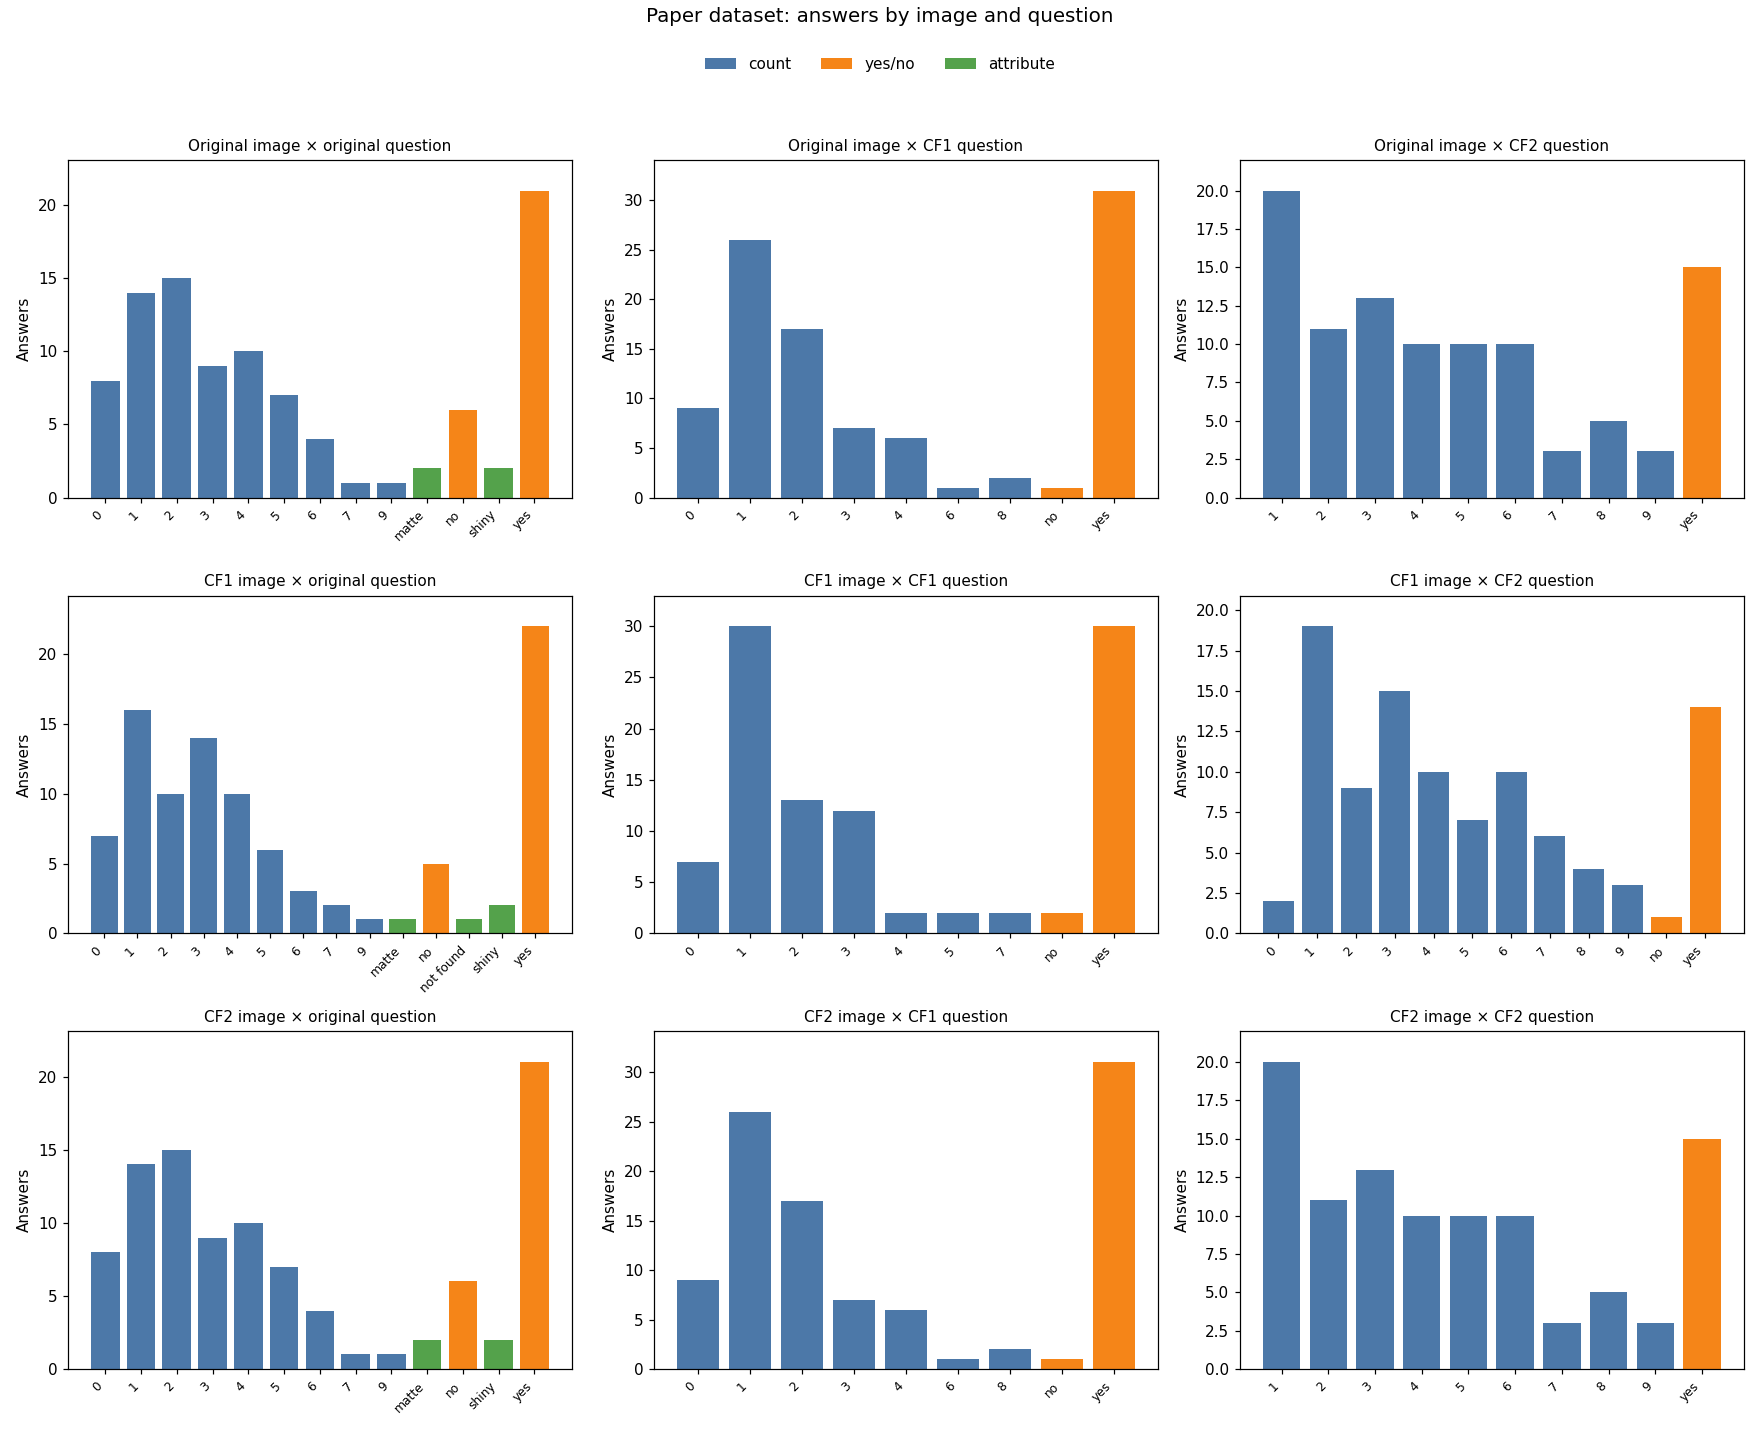

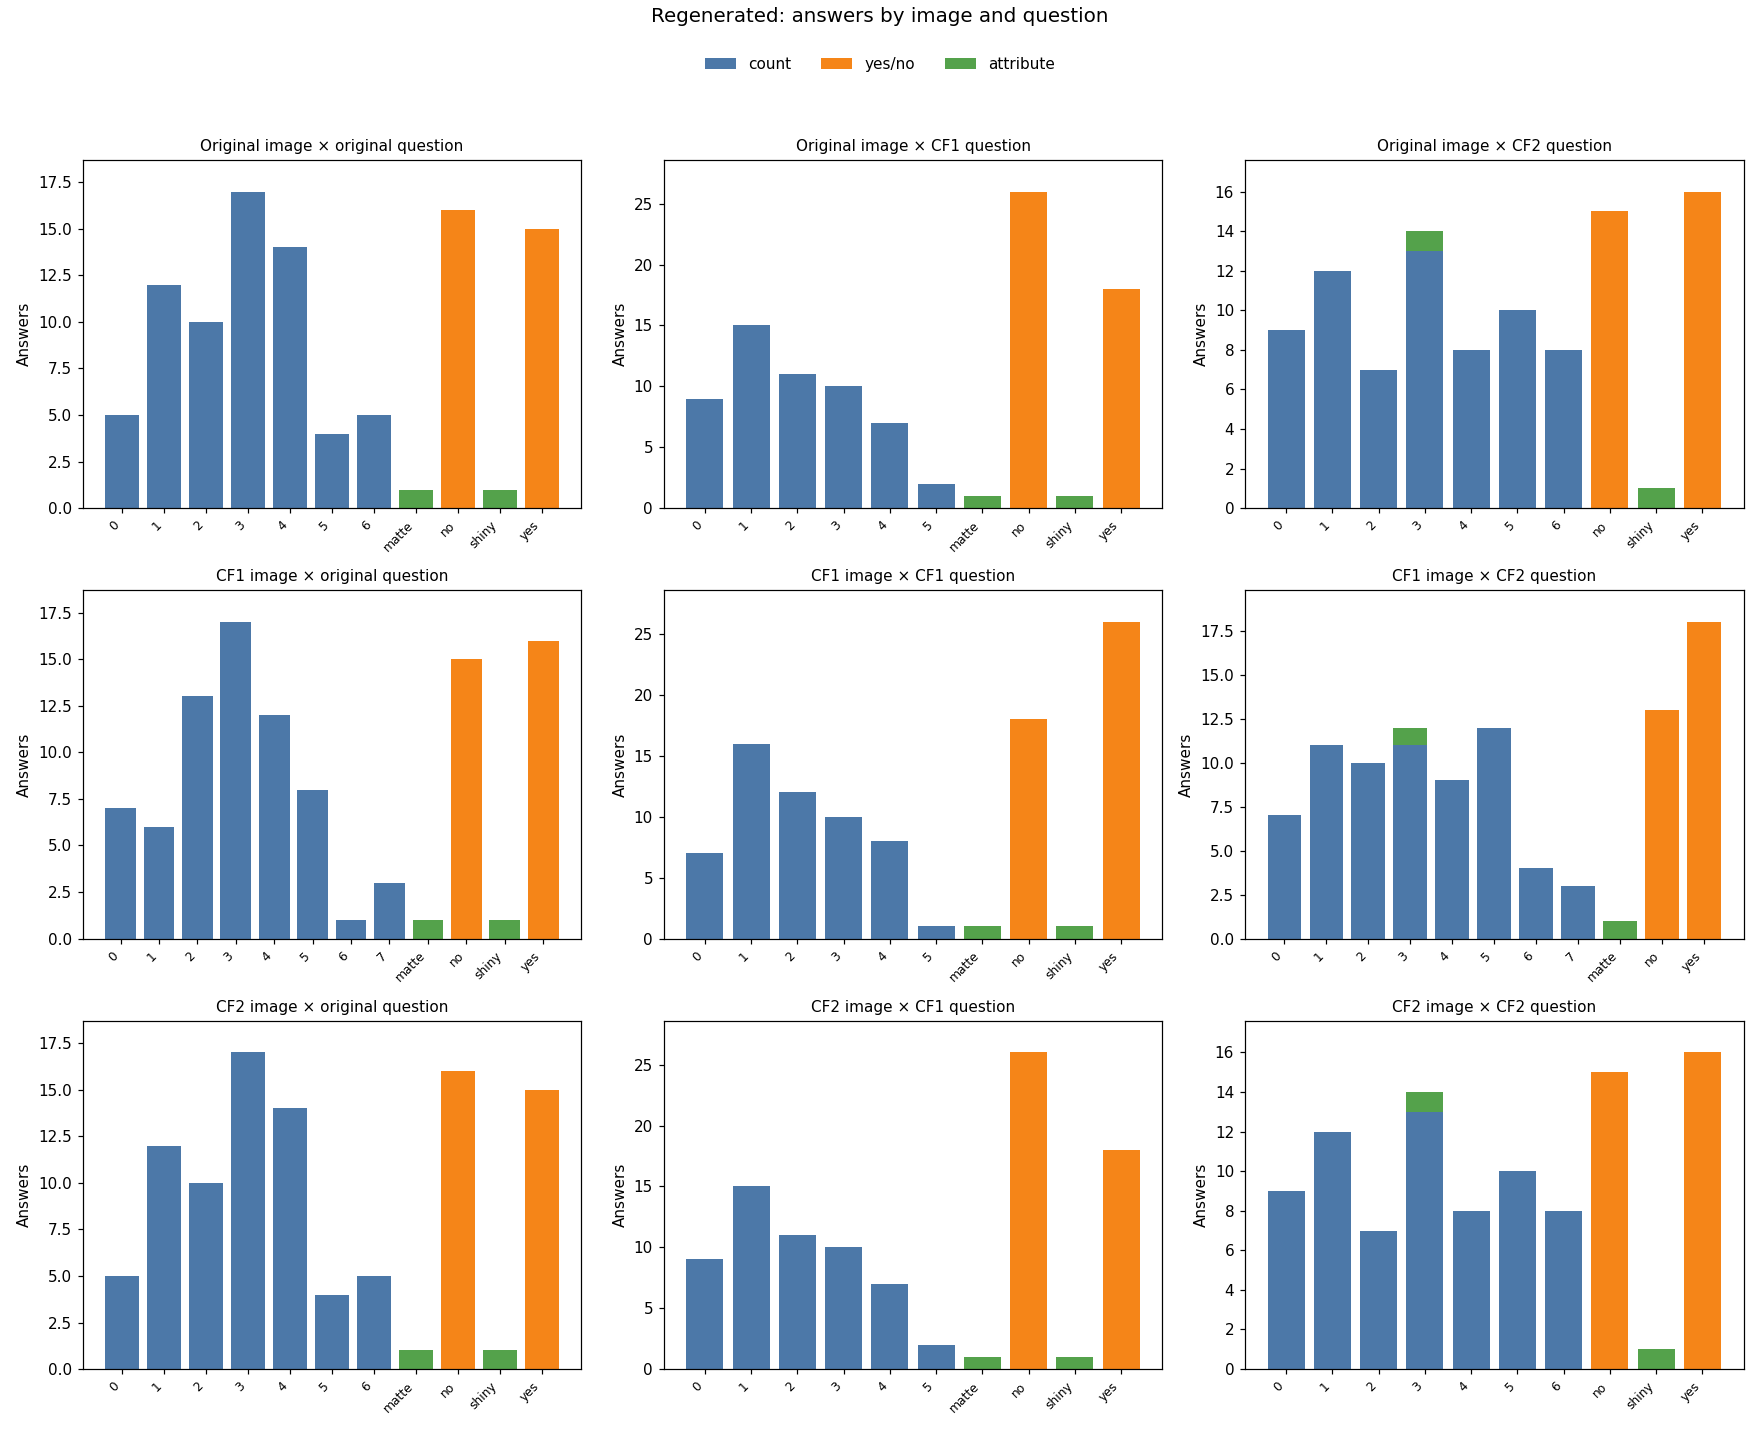

In [8]:
TYPE_ORDER = ["count", "yes/no", "attribute", "other"]
TYPE_COLORS = {"count": "#4C78A8", "yes/no": "#F58518", "attribute": "#54A24B", "other": "#B279A2"}


def plot_nine_cells(frame, version):
    present = set().union(*(frame[t].unique() for t in ("orig_type", "cf1_type_q", "cf2_type_q")))
    types = [t for t in TYPE_ORDER if t in present]
    fig = Figure(figsize=(16, 13))
    axes = fig.subplots(3, 3)
    for ax, (img, q, col, tcol) in zip(axes.ravel(), NINE_CELLS):
        counts = (
            frame.assign(answer=frame[col].replace("", "<empty>"))
            .groupby([tcol, "answer"]).size().unstack(fill_value=0)
            .reindex(types, fill_value=0)
        )
        x = range(len(counts.columns))
        bottom = [0] * len(counts.columns)
        for t in types:
            vals = counts.loc[t].tolist()
            ax.bar(x, vals, bottom=bottom, label=t, color=TYPE_COLORS[t])
            bottom = [b + v for b, v in zip(bottom, vals)]
        ax.set_xticks(list(x))
        ax.set_xticklabels(counts.columns, rotation=45, ha="right", fontsize=8)
        ax.set_title(f"{img} × {q}", fontsize=10)
        ax.set_ylabel("Answers")
        ax.set_ylim(0, max(bottom) * 1.1 if max(bottom) else 1)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.suptitle(f"{LABELS[version]}: answers by image and question", y=0.995, fontsize=13)
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.97), ncol=len(types), frameon=False)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    path = NOTEBOOK_DIR / f"answers_{version.replace('.', '_')}.png"
    fig.savefig(path, dpi=110)
    display(Image(filename=str(path)))


for v in [*RELEASES, *([REGEN] if REGEN else [])]:
    plot_nine_cells(FRAMES[v], v)

## Data defects

Unresolved answers, constant columns and duplicates are reported, not removed.

In [9]:
display(pd.DataFrame({
    LABELS[v]: {
        "Unresolved answers": RESULTS[v]["unresolved_n"],
        "Constant columns": ", ".join(c["column"] for c in RESULTS[v]["constant_columns"]) or "none",
        "Duplicate rows": RESULTS[v]["duplicate_rows"],
        "Repeated question triples": RESULTS[v]["duplicate_question_triples"],
        "CF1 difficulty / skill labels": len(RESULTS[v]["cf1_skill_values"]),
    }
    for v in VERSIONS
}))

unresolved = [dict(version=LABELS[v], **r) for v in VERSIONS for r in RESULTS[v]["unresolved_rows"]]
if unresolved:
    display(Markdown("**Unresolved answers**"))
    display(pd.DataFrame(unresolved))

,Paper dataset,"Regenerated, checks only",Regenerated
Unresolved answers,1,0,0
Constant columns,counterfactual1_question_difficulty,none,none
Duplicate rows,0,0,0
Repeated question triples,0,3,3
CF1 difficulty / skill labels,1,7,8


**Unresolved answers**

,version,row,cell,value,original_question,cf1_type
0,Paper dataset,85,CF1 image × original question,not found,Is the blue sphere matte or shiny?,change_color


## Generation cost

Why candidate triplets were rejected while generating the regenerated set.

In [10]:
acc = RESULTS[REGEN]["acceptance"] if REGEN else {}
if acc.get("source") != "instrumented":
    print("Rejection reasons are only recorded for the regenerated set.")
else:
    rejected = acc["attempts"] - acc["accepted"]
    reasons = pd.Series({k: v for k, v in acc["reject_reasons"].items() if k in REJECT_CATEGORY})
    by_category = reasons.groupby(reasons.index.map(REJECT_CATEGORY)).sum().sort_values(ascending=False)
    report = pd.DataFrame({"Rejected": by_category, "Share": (by_category / rejected).map(pct)})
    display(report)
    if by_category.sum() != rejected:
        print(f"Recorded reasons cover {by_category.sum():,} of {rejected:,} rejections.")
    if acc.get("quota_fallbacks"):
        print(f"Quota fallbacks recorded: {acc['quota_fallbacks']}.")

,Rejected,Share
No usable CF1 question template,7611,97.6%
Flip check,75,1.0%
Answer-balance quota,63,0.8%
Unresolved answer,53,0.7%


Quota fallbacks recorded: 2.


## Limitations

- The paper dataset and the regenerated set were produced by different versions of the generator, so differences between them are not the effect of any single change. The run without quotas isolates the quotas.
- Each set has about 100 triplets, so per-type rates rest on few triplets and intervals are wide.
- In the regenerated set, the flip rate, hold rate and yes/no balance are enforced by the generator. They describe the data; they are not independent measurements of how well the generator performs.
- Answer types are inferred from question text, so that all datasets are classified the same way.
- All scenes are synthetic (CLEVR assets). These results do not cover the COCO-based version in development.